# 03 - Build the 1km Analysis Grid

Builds a 1km x 1km grid over the Banten AOI in UTM 48S (EPSG:32748) - the spatial unit every other dataset gets aggregated onto later via zonal statistics. A cell is kept only if its centroid falls inside the actual Banten polygon, not just its bounding box, so the coastline doesn't end up padded with slivers.

Output: `datasets/processed/grid/grid_1km.gpkg`, one polygon per cell with a `grid_id`.

In [1]:
# add scripts/download to sys.path so we can `from common import ...`
import os, sys
from pathlib import Path

NOTEBOOK_DIR = Path(os.path.abspath("."))
if NOTEBOOK_DIR.name != "preprocessing":
    NOTEBOOK_DIR = NOTEBOOK_DIR / "scripts" / "preprocessing"
os.chdir(NOTEBOOK_DIR)

PROJECT_ROOT = NOTEBOOK_DIR.parents[1]
DOWNLOAD_DIR = PROJECT_ROOT / "scripts" / "download"
if str(DOWNLOAD_DIR) not in sys.path:
    sys.path.insert(0, str(DOWNLOAD_DIR))

print("cwd:", os.getcwd())

cwd: D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\scripts\preprocessing


## 1. Configuration

In [2]:
import geopandas as gpd

from common import RAW_DIR, PROCESSED_DIR, ensure_dir, get_logger

log = get_logger("build_grid")

CELL_SIZE_M = 1000  # 1km analysis grid
TARGET_CRS = "EPSG:32748"  # UTM 48S - used for the grid itself and any area/slope math

AOI_PATH = RAW_DIR / "boundaries" / "aoi_banten.geojson"
OUT_DIR = PROCESSED_DIR / "grid"
OUT_PATH = OUT_DIR / "grid_1km.gpkg"

## 2. Build the grid

In [3]:
import numpy as np
from shapely.geometry import box


def build_grid() -> gpd.GeoDataFrame:
    aoi = gpd.read_file(AOI_PATH).to_crs(TARGET_CRS)
    aoi_geom = aoi.geometry.iloc[0]
    minx, miny, maxx, maxy = aoi.total_bounds

    # snap the bounds to a clean multiple of the cell size so row/col indices are predictable
    minx = np.floor(minx / CELL_SIZE_M) * CELL_SIZE_M
    miny = np.floor(miny / CELL_SIZE_M) * CELL_SIZE_M

    n_cols = int(np.ceil((maxx - minx) / CELL_SIZE_M))
    n_rows = int(np.ceil((maxy - miny) / CELL_SIZE_M))
    log.info(
        "Candidate grid over the AOI bounding box: %d cols x %d rows = %d cells (before clipping)",
        n_cols, n_rows, n_cols * n_rows,
    )

    records = []
    for row in range(n_rows):
        y0 = miny + row * CELL_SIZE_M
        for col in range(n_cols):
            x0 = minx + col * CELL_SIZE_M
            cell = box(x0, y0, x0 + CELL_SIZE_M, y0 + CELL_SIZE_M)
            # keep a cell only if its centroid actually falls inside Banten - avoids
            # keeping a pile of slivers along the coastline/border
            if cell.centroid.within(aoi_geom):
                records.append({"grid_id": f"BTN_{row:04d}_{col:04d}", "row": row, "col": col, "geometry": cell})

    grid = gpd.GeoDataFrame(records, crs=TARGET_CRS)
    log.info("Kept %d cells with a centroid inside the Banten AOI", len(grid))
    return grid, aoi

## 3. Run it and save

In [4]:
ensure_dir(OUT_DIR)
grid, aoi = build_grid()

# centroid in lat/lon too - handy later for patch extraction, plotting, sanity checks
centroids_4326 = grid.geometry.centroid.to_crs("EPSG:4326")
grid["lon"] = centroids_4326.x
grid["lat"] = centroids_4326.y

grid.to_file(OUT_PATH, driver="GPKG")

grid_area_km2 = len(grid) * (CELL_SIZE_M / 1000) ** 2
aoi_area_km2 = aoi.geometry.area.iloc[0] / 1e6
print(f"Saved {OUT_PATH}")
print(f"  {len(grid)} cells, ~{grid_area_km2:,.0f} km2 covered by the grid")
print(f"  Banten AOI polygon area: ~{aoi_area_km2:,.0f} km2")
print(f"  coverage ratio (grid/AOI): {grid_area_km2 / aoi_area_km2:.2%}")

[build_grid] Candidate grid over the AOI bounding box: 186 cols x 136 rows = 25296 cells (before clipping)
[build_grid] Kept 9333 cells with a centroid inside the Banten AOI
[pyogrio._io] Created 9,333 records


Saved D:\Softwares\AnacondaProjects\GeoSuitability_AI_Analytics\datasets\processed\grid\grid_1km.gpkg
  9333 cells, ~9,333 km2 covered by the grid
  Banten AOI polygon area: ~9,342 km2
  coverage ratio (grid/AOI): 99.91%


## 4. Preview

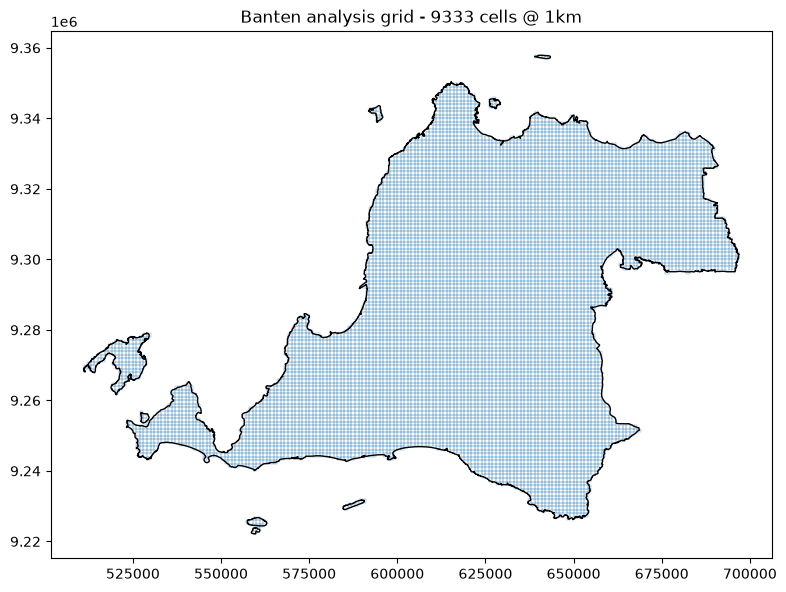

,grid_id,row,col,geometry,lon,lat
0,BTN_0000_0048,0,48,"POLYGON ((560000 9222000, 560000 9223000, 5590...",105.538731,-7.033623
1,BTN_0001_0048,1,48,"POLYGON ((560000 9223000, 560000 9224000, 5590...",105.538721,-7.024577
2,BTN_0001_0049,1,49,"POLYGON ((561000 9223000, 561000 9224000, 5600...",105.547775,-7.024567
3,BTN_0002_0049,2,49,"POLYGON ((561000 9224000, 561000 9225000, 5600...",105.547764,-7.015521
4,BTN_0002_0050,2,50,"POLYGON ((562000 9224000, 562000 9225000, 5610...",105.556818,-7.015511


In [5]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 8))
aoi.boundary.plot(ax=ax, color="black", linewidth=1)
grid.plot(ax=ax, facecolor="none", edgecolor="tab:blue", linewidth=0.2)
ax.set_title(f"Banten analysis grid - {len(grid)} cells @ 1km")
plt.tight_layout()
plt.show()

grid.head()